In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('../datasets/insurance.csv')


In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [14]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


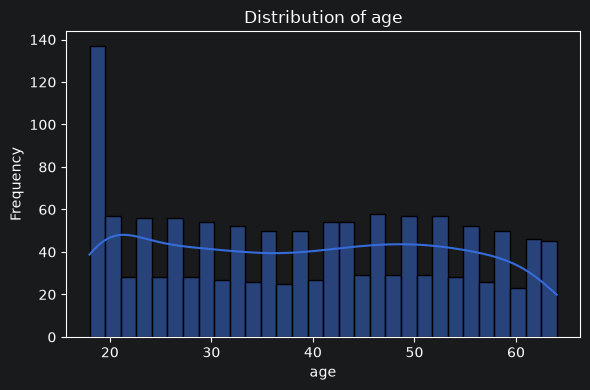

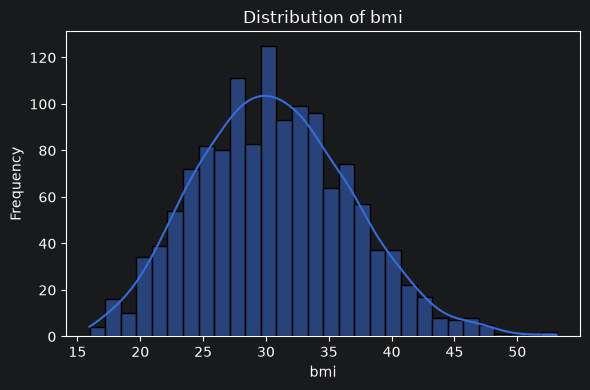

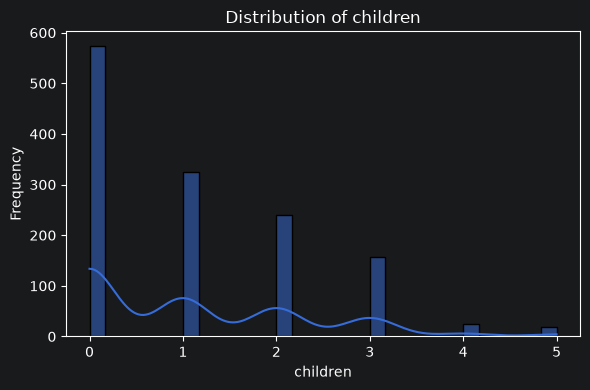

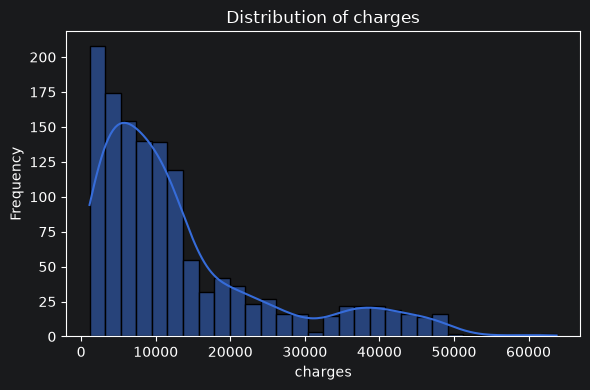

In [20]:
numerical_columns = ['age', 'bmi', 'children','charges' ]

for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()


<Axes: xlabel='children', ylabel='count'>

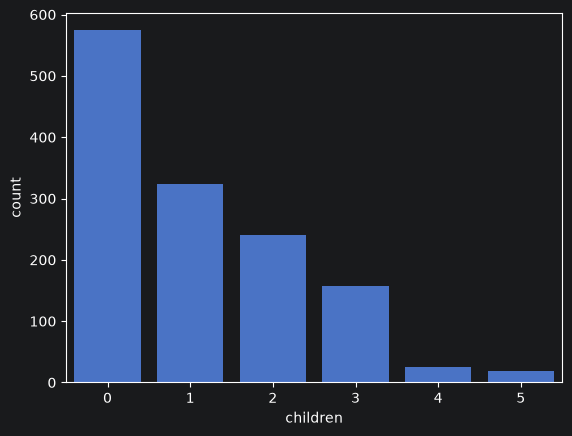

In [22]:
sns.countplot(x = df['children'])

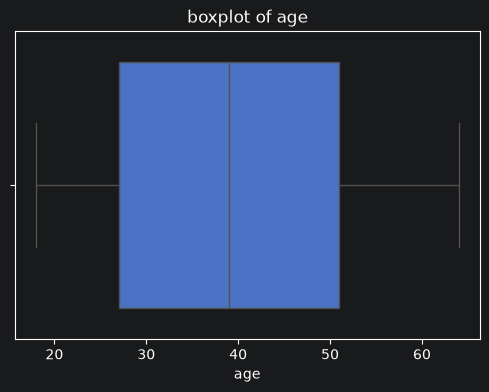

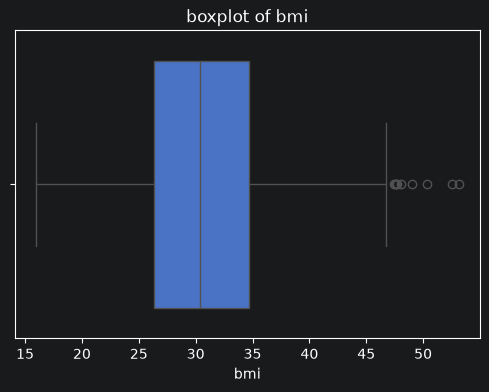

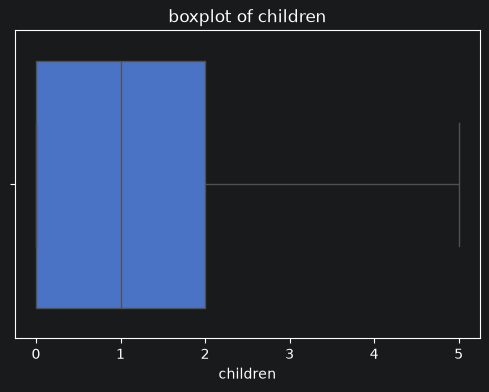

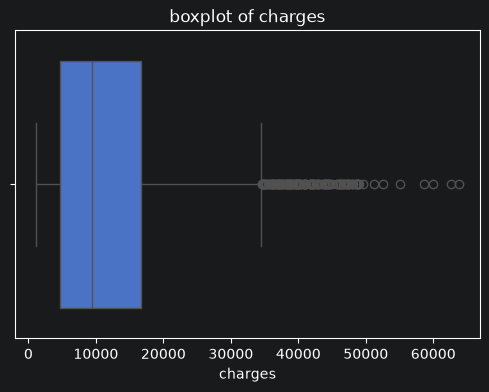

In [23]:
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x = df[col])
    plt.title(f"boxplot of {col}")

Text(0.5, 1.0, 'Correlation Heatmap')

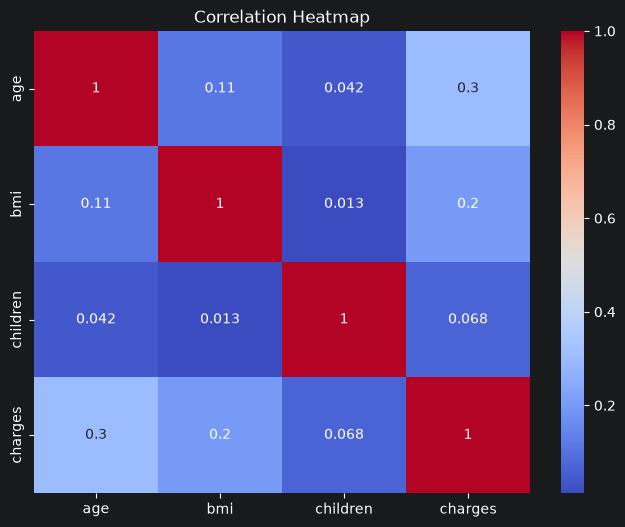

In [24]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')


## Data Cleaning and Preprocessing

In [29]:
df_cleaned = df.copy()

In [31]:
df_cleaned.drop_duplicates(inplace=True)

In [33]:
df_cleaned.shape

(1337, 7)

In [35]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [36]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [43]:
df_cleaned['sex'] = df_cleaned['sex'].map({ 'male': 0 , 'female': 1})
df_cleaned['smoker'] = df_cleaned['smoker'].map({'no': 0, 'yes': 1})

In [45]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [47]:
df_cleaned.rename(
    columns={
        'sex': 'is_female',
        'smoker': 'is_smoker'
    },
    inplace=True)

In [49]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


<Axes: xlabel='bmi', ylabel='Count'>

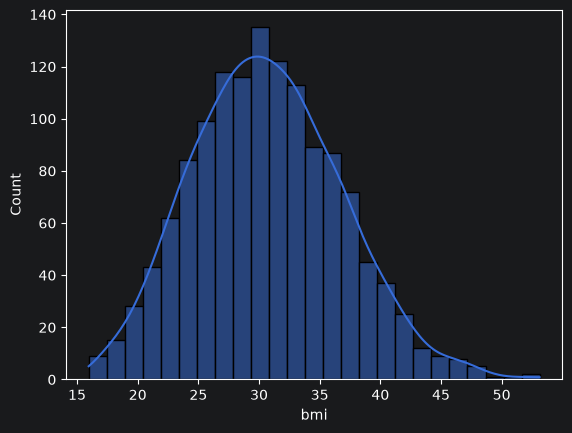

In [52]:
sns.histplot(df_cleaned['bmi'], kde=True)

In [53]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins=[0, 18.5, 24.9, 29.9, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight','Obese']
)

In [57]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges,bmi_category
0,19,1,27.900,0,1,southwest,16884.92400,Overweight
1,18,0,33.770,1,0,southeast,1725.55230,Obese
2,28,0,33.000,3,0,southeast,4449.46200,Obese
3,33,0,22.705,0,0,northwest,21984.47061,Normal
4,32,0,28.880,0,0,northwest,3866.85520,Overweight


In [62]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['region'], drop_first=True)

In [63]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,True,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,True,False,False


In [64]:
df_cleaned = df_cleaned.astype(int)

In [66]:
df_cleaned.dtypes

age                        int64
is_female                  int64
bmi                        int64
children                   int64
is_smoker                  int64
charges                    int64
bmi_category_Normal        int64
bmi_category_Overweight    int64
bmi_category_Obese         int64
region_northwest           int64
region_southeast           int64
region_southwest           int64
dtype: object

In [67]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,1,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0,1,0
2,28,0,33,3,0,4449,0,0,1,0,1,0
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,1,0,0


## Features Engineering and Extraction

In [69]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = ['age','bmi','children']
scaler = StandardScaler()
df_cleaned[cols_to_scale] = scaler.fit_transform(df_cleaned[cols_to_scale])

In [70]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,1,0,0,0,1
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,1,0
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,1,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,1,0,0


In [74]:
from scipy.stats import pearsonr

#
# Pearson Correlation Calculation
#

# List of features to check against target
selected_features = [
    'age', 'bmi', 'children', 'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

# Calculate Pearson correlation
correlations = {
    feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
    for feature in selected_features
}

# Calculate to DataFrame for display
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])

# Show the results
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_Obese,0.197660
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058046
8,bmi_category_Normal,-0.105656


In [77]:
cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

In [79]:
from scipy.stats import chi2_contingency

# Define significance level
alpha = 0.5

# Bin the target variable
df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'], q=4, labels=False)

# Run Chi-Square test
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], df_cleaned['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

# Convert to DataFrame
chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')


In [80]:
chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese,7.654464,0.05372,Reject Null (Keep Feature)
region_southwest,5.091893,0.165191,Reject Null (Keep Feature)
bmi_category_Normal,4.263673,0.234364,Reject Null (Keep Feature)
bmi_category_Overweight,4.201575,0.240504,Reject Null (Keep Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [83]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest,charges_bin
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,1,0,0,0,1,3
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,1,0,0
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,1,0,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0,3
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,1,0,0,0


In [84]:
final_df = df_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_category_Obese','region_northwest']]

In [85]:
final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese,region_northwest
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1,0
2,-0.799350,0,0.462463,1.580143,0,4449,1,1,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0,1
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0,1
...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1,0
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1,0
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,0


In [86]:
from sklearn.model_selection import train_test_split

In [87]:
X = final_df.drop('charges', axis=1)
y = final_df['charges']

In [88]:
X_train , X_test , y_train, y_test = train_test_split(X, y , test_size=0.2, random_state=42)

In [90]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [91]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[3483.27, 43.17, 667.64,...,-334.85,3055.34, -63.32]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','is_female','bmi',...,'region_southeast','bmi_category_Obese', 'region_northwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6921
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [92]:
y_pred = model.predict(X_test)

In [93]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

In [94]:
r2

0.8038720770710298

In [95]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / ( n - p - 1))

In [96]:
adjusted_r2

0.7978140717295944